# Modeling Human Activity States Using Hidden Markov Models

**Formative 2: Human Activity Recognition (HAR) with a from-scratch HMM**

Use case: a phone or wearable monitor for older adults living alone. It infers the wearer's activity
(*standing, walking, jumping, still*). It flags long periods of inactivity, and it flags sudden violent
movement that could be a fall or a seizure.

Pipeline:
1. **Data**: load the Sensor Logger exports (accelerometer and gyroscope), check and harmonise the sampling rate, trim, merge, clean.
2. **Features**: 2 s windows with 50 % overlap, time- and frequency-domain features, Z-score normalisation (fit on train only).
3. **HMM**: Gaussian-emission HMM written from scratch in numpy (forward/backward in log space, Viterbi, multi-sequence Baum-Welch).
4. **Evaluation**: unseen test recordings, with sensitivity, specificity, accuracy, a confusion matrix and decoded sequences.

Every number in the report comes from this notebook. Run it top to bottom (`Kernel → Restart & Run All`).

In [1]:
from __future__ import annotations

import json
import itertools
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import linear_sum_assignment

SEED = 42
rng = np.random.default_rng(SEED)

# --- paths -----------------------------------------------------------------
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_TRAIN = ROOT / "data" / "raw" / "train"
RAW_TEST = ROOT / "data" / "raw" / "test"
LABELS_DIR = ROOT / "data" / "labels"
PROC = ROOT / "data" / "processed"
FIG = ROOT / "figures"
for p in (PROC / "train", PROC / "test", FIG):
    p.mkdir(parents=True, exist_ok=True)

# --- global constants ------------------------------------------------------
ACTIVITIES = ["standing", "walking", "jumping", "still"]   # hidden states, fixed order
FS = 50.0            # common (target) sampling rate in Hz
TRIM_S = 2.0         # seconds trimmed from each end (start/stop button taps)
WIN_S = 2.0          # window length in seconds
OVERLAP = 0.5        # fractional window overlap
WIN = int(WIN_S * FS)            # samples per window, derived from FS
STEP = int(WIN * (1 - OVERLAP))  # hop size in samples

PALETTE = dict(zip(ACTIVITIES, ["#4C72B0", "#55A868", "#C44E52", "#8172B2"]))
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight"})

def savefig(fig: plt.Figure, name: str) -> None:
    # Save a figure as PNG in figures/ (it is also shown inline).
    fig.savefig(FIG / f"{name}.png")

RESULTS: dict = {}   # every number the report uses gets collected here and dumped to JSON
print(f"FS={FS} Hz, window={WIN} samples ({WIN_S}s), step={STEP} samples, FFT resolution={FS/WIN:.2f} Hz")

FS=50.0 Hz, window=100 samples (2.0s), step=50 samples, FFT resolution=0.50 Hz


## 1. Data Collection and Pre-processing

Each recording is an unzipped **Sensor Logger (iOS)** export: one folder per recording, named
`<label>_<NN>-<timestamp>`. We use `Accelerometer.csv` (iOS *user acceleration*, gravity removed, in m/s²)
and `Gyroscope.csv` (rad/s). Columns come in the order `time, seconds_elapsed, z, y, x`, so we always select them **by name**.
The two sensors share timestamps, so we merge them with an inner join on `time`.

Raw files are never modified. All cleaning happens here, and the cleaned outputs go to `data/processed/`.

In [2]:
def parse_label(folder: Path) -> str:
    """Activity label = part of the folder name before the first '_'."""
    return folder.name.split("_")[0]


def read_metadata(folder: Path) -> dict:
    """Read device name and the configured sample period from Metadata.csv."""
    meta = pd.read_csv(folder / "Metadata.csv").iloc[0]
    periods = [float(p) for p in str(meta["sampleRateMs"]).split("|") if p not in ("", "nan")]
    return {"device": meta["device name"], "configured_ms": periods[0] if periods else np.nan}


def load_recording(folder: Path) -> pd.DataFrame:
    """Load one Sensor Logger recording and merge accelerometer + gyroscope on `time`.

    Returns a DataFrame with columns t (s, starting at 0), acc_x/y/z (m/s^2), gyro_x/y/z (rad/s).
    """
    acc = pd.read_csv(folder / "Accelerometer.csv")[["time", "x", "y", "z"]]
    gyr = pd.read_csv(folder / "Gyroscope.csv")[["time", "x", "y", "z"]]
    acc = acc.rename(columns={c: f"acc_{c}" for c in "xyz"})
    gyr = gyr.rename(columns={c: f"gyro_{c}" for c in "xyz"})
    df = acc.merge(gyr, on="time", how="inner").sort_values("time").drop_duplicates("time")
    df.insert(0, "t", (df["time"] - df["time"].iloc[0]) / 1e9)
    return df.drop(columns="time").reset_index(drop=True)


def detect_rate(t: np.ndarray) -> float:
    """Sampling rate (Hz) estimated from the median timestamp difference."""
    return float(1.0 / np.median(np.diff(t)))

In [3]:
def inventory(raw_dir: Path) -> pd.DataFrame:
    """List every recording folder with label, device, configured and detected rate, and duration."""
    rows = []
    for folder in sorted(p for p in raw_dir.iterdir() if p.is_dir()):
        df = load_recording(folder)
        meta = read_metadata(folder)
        rows.append({
            "recording": folder.name.split("-")[0],
            "folder": folder.name,
            "label": parse_label(folder),
            "device": meta["device"],
            "configured_hz": 1000.0 / meta["configured_ms"],
            "detected_hz": detect_rate(df["t"].to_numpy()),
            "n_samples": len(df),
            "raw_duration_s": df["t"].iloc[-1],
        })
    return pd.DataFrame(rows)

train_inv = inventory(RAW_TRAIN)
unexpected = train_inv.loc[~train_inv["label"].isin(ACTIVITIES), "folder"].tolist()
assert not unexpected, f"Folders with unexpected labels: {unexpected}"
print("All training folder labels are valid:", sorted(train_inv["label"].unique()))
train_inv.head()

All training folder labels are valid: ['jumping', 'standing', 'still', 'walking']


,recording,folder,label,device,configured_hz,detected_hz,n_samples,raw_duration_s
0,jumping_01,jumping_01-2026-10-30_10-09-52,jumping,iPhone XS,50.0,49.769072,674,13.522277
1,jumping_02,jumping_02-2026-10-30_10-10-09,jumping,iPhone XS,50.0,49.770558,824,16.536120
2,jumping_03,jumping_03-2026-10-30_10-10-33,jumping,iPhone XS,50.0,49.770558,659,13.220806
3,jumping_04,jumping_04-2026-10-30_10-10-48,jumping,iPhone XS,50.0,49.769072,631,12.658296
4,jumping_05,jumping_05-2026-10-30_10-11-41,jumping,iPhone XS,50.0,49.766099,665,13.342264


### 1.1 Sampling-rate check and harmonisation

The brief asks us to harmonise sampling rates across phones. We do not trust the configured value alone.
We **detect** each file's rate from its timestamps (the median Δt), compare it to `sampleRateMs` in `Metadata.csv`,
and then resample *every* recording onto a uniform 50 Hz grid with linear interpolation.
This step is needed when phones differ (for example a 100 Hz Android phone and a 50 Hz iPhone).
It also removes small timestamp jitter, so that a 100-sample window is always exactly 2.0 s
and FFT bins sit at the same frequencies for every file.

,files,configured_hz,detected_hz_mean,detected_hz_min,detected_hz_max
device,,,,,
iPhone XS,48,50.0,49.77,49.76,49.77


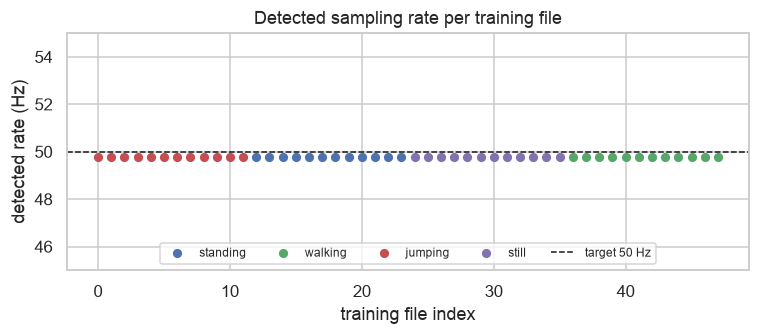

In [4]:
rate_summary = (train_inv.groupby("device")
                .agg(files=("folder", "count"), configured_hz=("configured_hz", "mean"),
                     detected_hz_mean=("detected_hz", "mean"), detected_hz_min=("detected_hz", "min"),
                     detected_hz_max=("detected_hz", "max"))
                .round(2))
display(rate_summary)

RESULTS["devices"] = rate_summary.reset_index().to_dict(orient="records")
RESULTS["detected_hz_range"] = [round(train_inv.detected_hz.min(), 2), round(train_inv.detected_hz.max(), 2)]

fig, ax = plt.subplots(figsize=(8, 2.8))
for lab in ACTIVITIES:
    sub = train_inv[train_inv.label == lab]
    ax.scatter(sub.index, sub.detected_hz, label=lab, color=PALETTE[lab], s=25)
ax.axhline(FS, ls="--", c="k", lw=1, label=f"target {FS:.0f} Hz")
ax.set(xlabel="training file index", ylabel="detected rate (Hz)", title="Detected sampling rate per training file",
       ylim=(FS - 5, FS + 5))
ax.legend(ncol=5, fontsize=8, loc="lower center")
savefig(fig, "fig_sampling_rates"); plt.show()

In [5]:
def resample(df: pd.DataFrame, fs: float = FS) -> pd.DataFrame:
    """Resample all signal columns onto a uniform grid at `fs` Hz with linear interpolation.

    Harmonises phones with different (or jittery) sampling rates. Grid: 0, 1/fs, ..., <= last timestamp.
    """
    t = df["t"].to_numpy()
    grid = np.arange(0.0, t[-1], 1.0 / fs)
    out = {"t": grid}
    for col in df.columns.drop("t"):
        out[col] = np.interp(grid, t, df[col].to_numpy())
    return pd.DataFrame(out)


def trim(df: pd.DataFrame, seconds: float = TRIM_S) -> pd.DataFrame:
    """Drop the first and last `seconds` (phone taps at start/stop), then re-zero time."""
    out = df[(df["t"] >= seconds) & (df["t"] <= df["t"].iloc[-1] - seconds)].copy()
    out["t"] -= out["t"].iloc[0]
    return out.reset_index(drop=True)


def clean_recording(folder: Path) -> pd.DataFrame:
    """Full cleaning chain: load+merge -> drop NaNs -> resample to FS -> trim lead-in/out."""
    df = load_recording(folder).dropna()
    return trim(resample(df, FS), TRIM_S)

In [6]:
SIGNALS = ["acc_x", "acc_y", "acc_z", "gyro_x", "gyro_y", "gyro_z"]

train_recs: dict[str, pd.DataFrame] = {}
for _, row in train_inv.iterrows():
    df = clean_recording(RAW_TRAIN / row.folder)
    df.insert(1, "label", row.label)
    train_recs[row.recording] = df
    df.to_csv(PROC / "train" / f"{row.recording}.csv", index=False)

train_inv["clean_duration_s"] = [train_recs[r]["t"].iloc[-1] + 1 / FS for r in train_inv.recording]
n_nan = sum(int(df[SIGNALS].isna().sum().sum()) for df in train_recs.values())
print(f"Cleaned {len(train_recs)} recordings -> data/processed/train/  (NaNs remaining: {n_nan})")

summary = (train_inv.groupby("label")
           .agg(files=("folder", "count"), raw_seconds=("raw_duration_s", "sum"),
                clean_seconds=("clean_duration_s", "sum"), mean_clean_s=("clean_duration_s", "mean"))
           .reindex(ACTIVITIES).round(1))
summary.loc["TOTAL"] = [summary.files.sum(), summary.raw_seconds.sum(), summary.clean_seconds.sum(),
                        train_inv.clean_duration_s.mean().round(1)]
display(summary)

MIN_S = 90.0
for lab in ACTIVITIES:
    s = summary.loc[lab, "clean_seconds"]
    status = "OK" if s >= MIN_S else f"SHORT by {MIN_S - s:.1f} s -> record more"
    print(f"{lab:9s}: {s:6.1f} s of clean data (>= {MIN_S:.0f} s required) -> {status}")

RESULTS["train_summary"] = summary.reset_index().rename(columns={"index": "label"}).to_dict(orient="records")
RESULTS["n_train_files"] = int(len(train_inv))
RESULTS["clean_duration_range"] = [round(train_inv.clean_duration_s.min(), 2), round(train_inv.clean_duration_s.max(), 2)]

Cleaned 48 recordings -> data/processed/train/  (NaNs remaining: 0)


,files,raw_seconds,clean_seconds,mean_clean_s
label,,,,
standing,12,165.6,117.8,9.8
walking,12,163.7,115.9,9.7
jumping,12,163.4,115.6,9.6
still,12,162.2,114.4,9.5
TOTAL,48,654.9,463.7,9.7


standing :  117.8 s of clean data (>= 90 s required) -> OK
walking  :  115.9 s of clean data (>= 90 s required) -> OK
jumping  :  115.6 s of clean data (>= 90 s required) -> OK
still    :  114.4 s of clean data (>= 90 s required) -> OK


### 1.2 Raw signal visualisation

One cleaned recording per activity. The scales differ a lot: *still* (phone on a table) is almost flat
(only sensor noise), while *jumping* produces large spikes (around ±40 m/s²) at the landing of each jump.

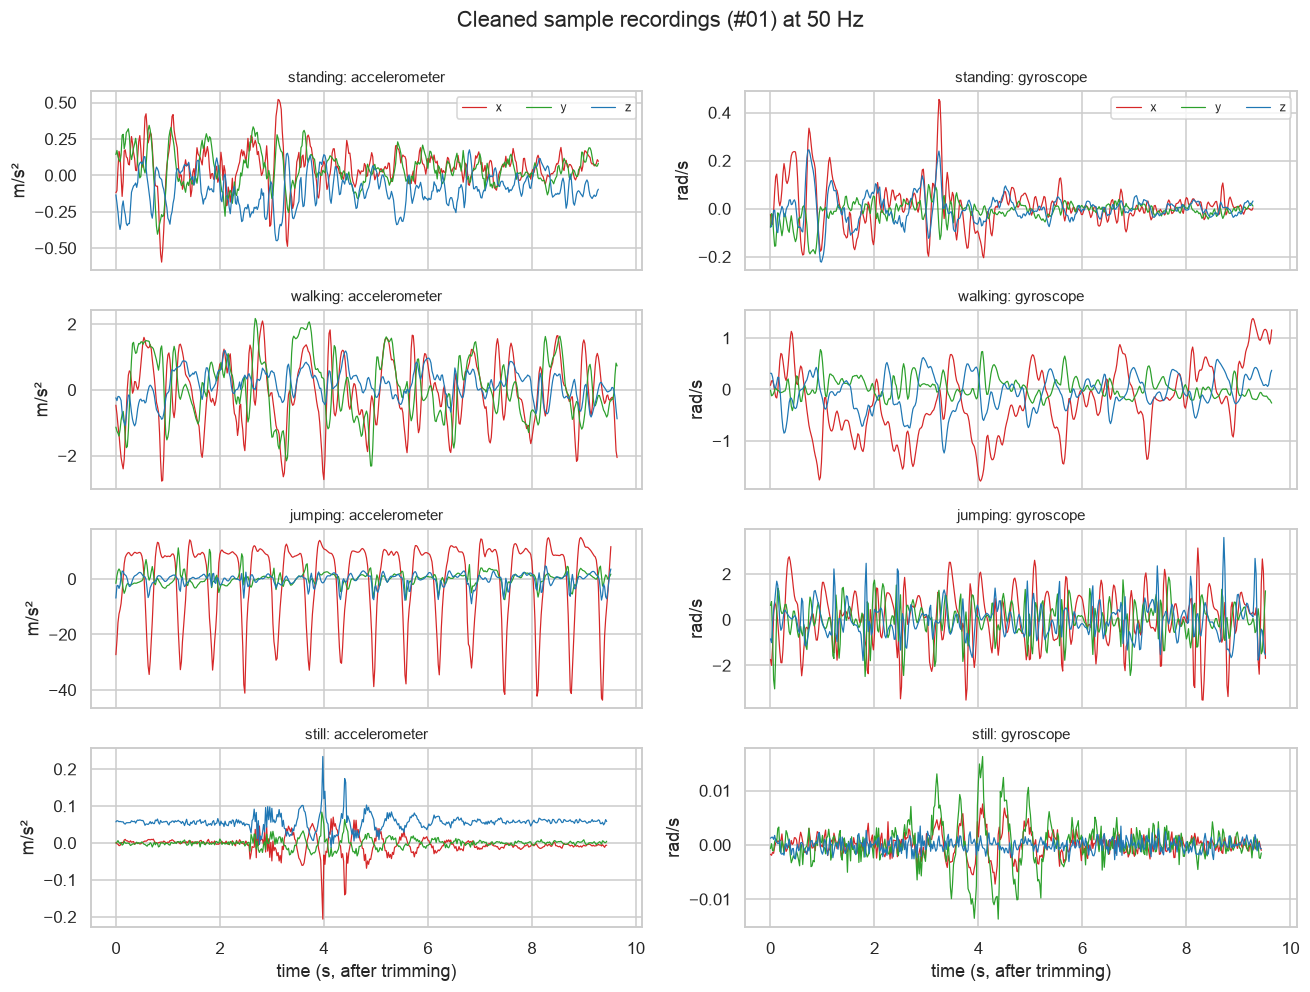

In [7]:
def plot_raw_examples(recs: dict[str, pd.DataFrame], idx: str = "01") -> plt.Figure:
    """Grid of acc / gyro x-y-z traces, one row per activity."""
    fig, axes = plt.subplots(len(ACTIVITIES), 2, figsize=(12, 9), sharex=True)
    for i, lab in enumerate(ACTIVITIES):
        df = recs[f"{lab}_{idx}"]
        for j, sensor in enumerate(["acc", "gyro"]):
            ax = axes[i, j]
            for axis, c in zip("xyz", ["tab:red", "tab:green", "tab:blue"]):
                ax.plot(df.t, df[f"{sensor}_{axis}"], lw=0.8, c=c, label=axis)
            unit = "m/s²" if sensor == "acc" else "rad/s"
            ax.set_title(f"{lab}: {'accelerometer' if sensor == 'acc' else 'gyroscope'}", fontsize=10)
            ax.set_ylabel(unit)
            if i == 0: ax.legend(ncol=3, fontsize=8, loc="upper right")
    for ax in axes[-1]: ax.set_xlabel("time (s, after trimming)")
    fig.suptitle(f"Cleaned sample recordings (#{idx}) at {FS:.0f} Hz", y=1.0)
    fig.tight_layout()
    return fig

fig = plot_raw_examples(train_recs); savefig(fig, "fig_raw_samples"); plt.show()

### 1.3 Windowing

Window length is derived from the sampling rate: `WIN = int(2.0 * FS)` = **100 samples (2 s)**, hop = 50 samples (**50 % overlap**, one observation per second).

Why 2 s:
* Walking is about 2 steps/s and our jumping is about 1.5–2 jumps/s (see the raw plots), so a 2 s window always holds **at least 2 full cycles** of each periodic activity. Its mean, variance and dominant frequency are then stable.
* At 50 Hz, a 100-sample FFT gives a frequency resolution of **FS/N = 0.5 Hz**, fine enough to separate walking (dominant frequency of the acceleration magnitude around 1–2.5 Hz) from jumping (around 3.5–4 Hz, because each jump has two impacts, take-off and landing) and from the random, broadband peak of *still*.
* A shorter window (1 s) would hold only 1–2 cycles. A longer one (4 s) would blur the transitions and leave only 2–3 windows per 9.5 s recording.
* 50 % overlap doubles the number of observations without new recordings, and gives the HMM a regular 1 s time step.

Windows are built **per recording**, so no window ever spans two recordings.

In [8]:
def window_signal(df: pd.DataFrame, win: int = WIN, step: int = STEP) -> list[pd.DataFrame]:
    """Split ONE recording into overlapping fixed-length windows (never crosses recordings)."""
    return [df.iloc[s:s + win] for s in range(0, len(df) - win + 1, step)]

n_per_rec = {r: len(window_signal(df)) for r, df in train_recs.items()}
print(f"windows per training recording: min={min(n_per_rec.values())}, max={max(n_per_rec.values())}, "
      f"total={sum(n_per_rec.values())}")

windows per training recording: min=7, max=11, total=392


## 2. Feature Extraction (time and frequency domain)

Note: iOS `Accelerometer.csv` already has **gravity removed**, so the axis *means* are about 0 for every activity
and carry no orientation information. The useful information is in **how much** and **how periodically** the phone moves.
Scale features (std, RMS, SMA, spectral energy) span about 3 orders of magnitude (still ≈ 0.005 m/s² vs jumping ≈ 10 m/s²),
so we take `log10` of them. This makes their per-class distributions close to Gaussian, which suits the Gaussian HMM emissions.

| Feature | Domain | Why it separates the activities |
|---|---|---|
| `acc_rms` (log) | time | Overall movement intensity: still ≪ standing < walking ≪ jumping |
| `acc_std_x/y/z` (log) | time | Per-axis variability. Jumping is dominated by the vertical axis, walking spreads over all axes |
| `acc_sma` (log) | time | Signal Magnitude Area, a standard activity-energy measure that is robust to orientation |
| `acc_corr_xy/xz/yz` | time | Axis coupling: jumping moves the axes together (strong correlation), noise on *still* is uncorrelated |
| `gyro_rms` (log) | time | Rotation intensity. Separates body sway (standing) from a phone lying on a table (still) |
| `gyro_std_x/y/z` (log) | time | Per-axis rotation variability. Walking makes the hips rotate in a typical way |
| `acc_dom_freq`, `gyro_dom_freq` | frequency | Dominant FFT frequency of the magnitude: walking ≈ 1–2.5 Hz, jumping ≈ 3.5–4 Hz (two impacts per jump), noise-driven and widely spread for still |
| `acc_spec_energy` (log) | frequency | Energy of the FFT spectrum (excluding DC): how much power the movement has |
| `acc_spec_entropy`, `gyro_spec_entropy` | frequency | Periodic movement gives a peaked spectrum (low entropy), noise gives a flat one (high entropy) |

In [9]:
EPS = 1e-6

def _spectrum(sig: np.ndarray, fs: float = FS) -> tuple[np.ndarray, np.ndarray]:
    """One-sided power spectrum of a de-meaned, Hann-windowed signal (DC bin removed)."""
    x = (sig - sig.mean()) * np.hanning(len(sig))
    power = np.abs(np.fft.rfft(x)) ** 2 / len(sig)
    freqs = np.fft.rfftfreq(len(sig), d=1.0 / fs)
    return freqs[1:], power[1:]


def _safe_corr(a: np.ndarray, b: np.ndarray) -> float:
    """Pearson correlation, 0 if either signal is constant."""
    if a.std() < 1e-12 or b.std() < 1e-12:
        return 0.0
    return float(np.corrcoef(a, b)[0, 1])


def extract_features(w: pd.DataFrame, fs: float = FS) -> dict[str, float]:
    """Compute the time- and frequency-domain feature vector for one window."""
    f: dict[str, float] = {}
    acc = w[["acc_x", "acc_y", "acc_z"]].to_numpy()
    gyr = w[["gyro_x", "gyro_y", "gyro_z"]].to_numpy()
    acc_mag, gyr_mag = np.linalg.norm(acc, axis=1), np.linalg.norm(gyr, axis=1)

    # ---- time domain ----
    f["acc_rms"] = np.log10(np.sqrt(np.mean(acc_mag ** 2)) + EPS)
    for i, ax in enumerate("xyz"):
        f[f"acc_std_{ax}"] = np.log10(acc[:, i].std() + EPS)
    f["acc_sma"] = np.log10(np.abs(acc).sum(axis=1).mean() + EPS)
    for (i, a), (j, b) in itertools.combinations(enumerate("xyz"), 2):
        f[f"acc_corr_{a}{b}"] = _safe_corr(acc[:, i], acc[:, j])
    f["gyro_rms"] = np.log10(np.sqrt(np.mean(gyr_mag ** 2)) + EPS)
    for i, ax in enumerate("xyz"):
        f[f"gyro_std_{ax}"] = np.log10(gyr[:, i].std() + EPS)

    # ---- frequency domain (on the magnitude, which does not depend on orientation) ----
    for name, mag in (("acc", acc_mag), ("gyro", gyr_mag)):
        freqs, p = _spectrum(mag, fs)
        f[f"{name}_dom_freq"] = float(freqs[np.argmax(p)])
        pn = p / (p.sum() + 1e-20)
        f[f"{name}_spec_entropy"] = float(-(pn * np.log2(pn + 1e-20)).sum() / np.log2(len(pn)))
        if name == "acc":
            f["acc_spec_energy"] = np.log10(p.sum() + EPS)
    return f

FEATURES = list(extract_features(next(iter(train_recs.values())).iloc[:WIN]).keys())
TIME_FEATS = [c for c in FEATURES if not any(k in c for k in ("dom_freq", "spec_"))]
FREQ_FEATS = [c for c in FEATURES if c not in TIME_FEATS]
print(f"{len(FEATURES)} features: {len(TIME_FEATS)} time-domain, {len(FREQ_FEATS)} frequency-domain")
print("time:", TIME_FEATS); print("freq:", FREQ_FEATS)
RESULTS["features"] = {"time": TIME_FEATS, "freq": FREQ_FEATS}

17 features: 12 time-domain, 5 frequency-domain
time: ['acc_rms', 'acc_std_x', 'acc_std_y', 'acc_std_z', 'acc_sma', 'acc_corr_xy', 'acc_corr_xz', 'acc_corr_yz', 'gyro_rms', 'gyro_std_x', 'gyro_std_y', 'gyro_std_z']
freq: ['acc_dom_freq', 'acc_spec_entropy', 'acc_spec_energy', 'gyro_dom_freq', 'gyro_spec_entropy']


In [10]:
def features_for_recording(df: pd.DataFrame, rec_id: str) -> pd.DataFrame:
    """Feature table for one recording: one row per window, with label (majority vote) and window centre time."""
    rows = []
    for k, w in enumerate(window_signal(df)):
        row = extract_features(w)
        row.update(recording=rec_id, win_idx=k, t_center=float(w["t"].mean()),
                   label=w["label"].mode().iloc[0])
        rows.append(row)
    return pd.DataFrame(rows)

train_feat = pd.concat([features_for_recording(df, r) for r, df in train_recs.items()], ignore_index=True)
assert not train_feat[FEATURES].isna().any().any(), "NaN in training features"
train_feat.to_csv(PROC / "features_train.csv", index=False)

win_counts = train_feat.label.value_counts().reindex(ACTIVITIES)
print("Training windows per activity:"); print(win_counts.to_string())
RESULTS["train_windows"] = win_counts.to_dict()

Training windows per activity:
label
standing    100
walking      98
jumping      98
still        96


### 2.1 Normalisation (Z-score)

The features have different units and scales: log m/s², log rad/s, Hz, unit-less correlations and entropies.
Without scaling, the features with the largest numeric range would dominate the Gaussian log-likelihood.
We use **Z-score** standardisation, $z = (x-\mu_{train})/\sigma_{train}$:
* it puts every feature on a comparable scale (mean 0, std 1), so each one gets equal weight in the diagonal-Gaussian emissions;
* it keeps the shape of the distribution (unlike min-max scaling, which outliers such as jump spikes would squash);
* standardised inputs keep the variances near 1, which makes the variance floor meaningful and the EM updates numerically well conditioned.

μ and σ are fitted **on the training windows only** and reused unchanged for the test data, so no test information leaks into training.
They are saved to `data/processed/scaler.json`.

In [11]:
class ZScaler:
    """Minimal Z-score scaler fitted on training data only."""

    def fit(self, X: pd.DataFrame) -> "ZScaler":
        self.mean_ = X.mean(); self.std_ = X.std(ddof=0).replace(0, 1.0)
        return self

    def transform(self, X: pd.DataFrame) -> pd.DataFrame:
        return (X - self.mean_) / self.std_

    def to_json(self, path: Path) -> None:
        path.write_text(json.dumps({"mean": self.mean_.to_dict(), "std": self.std_.to_dict()}, indent=2))


def normalize(train: pd.DataFrame, others: list[pd.DataFrame] = ()) -> tuple[ZScaler, pd.DataFrame, list]:
    """Fit a Z-scaler on `train[FEATURES]` and apply it to train and every other table."""
    sc = ZScaler().fit(train[FEATURES])
    return sc, sc.transform(train[FEATURES]), [sc.transform(o[FEATURES]) for o in others]

scaler, Ztrain, _ = normalize(train_feat)
scaler.to_json(PROC / "scaler.json")
print("train Z mean ~0:", np.allclose(Ztrain.mean(), 0, atol=1e-9), "| std ~1:", np.allclose(Ztrain.std(ddof=0), 1))

train Z mean ~0: True | std ~1: True


### 2.2 Feature justification plots

The box plots show how each feature separates the activities. The correlation heatmap shows which features carry overlapping information.

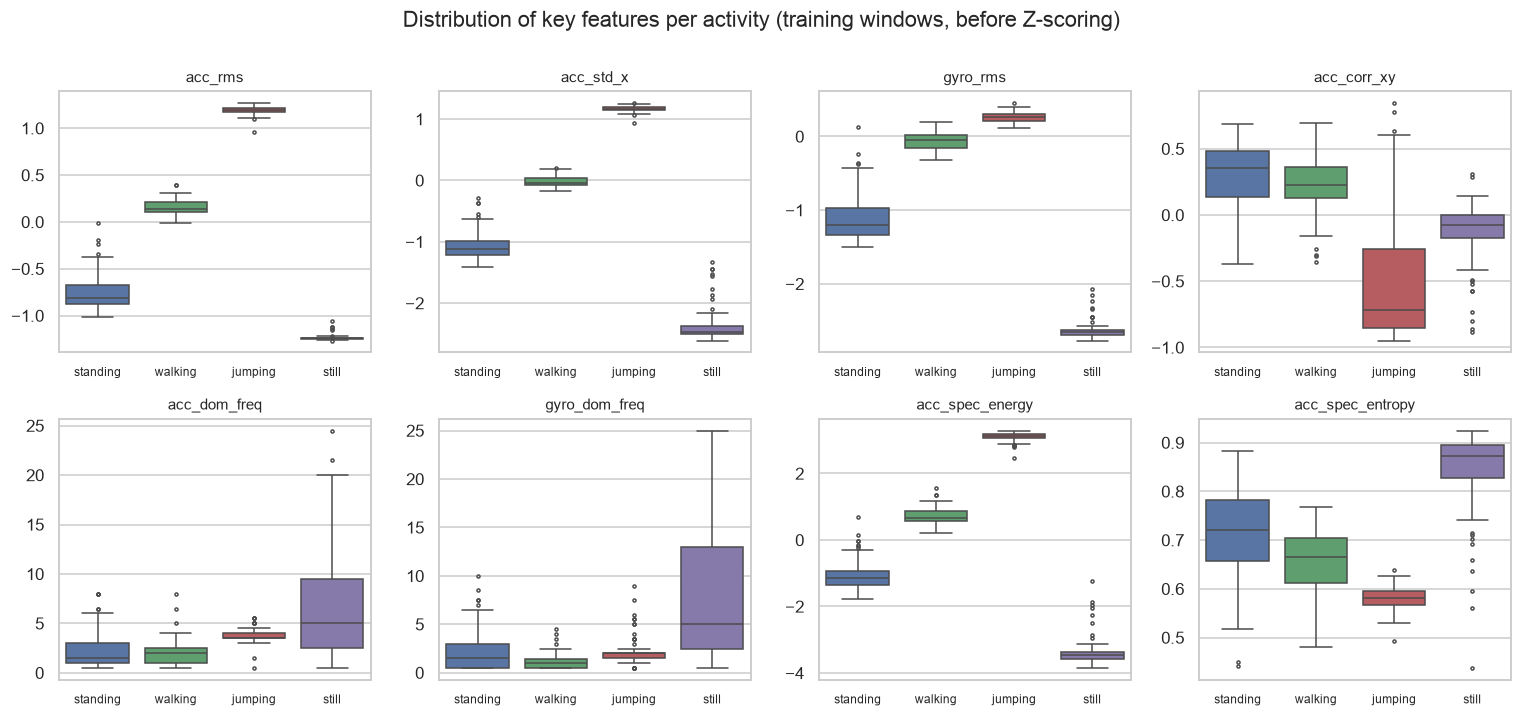

In [12]:
SHOW = ["acc_rms", "acc_std_x", "gyro_rms", "acc_corr_xy", "acc_dom_freq", "gyro_dom_freq",
        "acc_spec_energy", "acc_spec_entropy"]
fig, axes = plt.subplots(2, 4, figsize=(14, 6.5))
for ax, feat in zip(axes.ravel(), SHOW):
    sns.boxplot(data=train_feat, x="label", y=feat, order=ACTIVITIES, hue="label", palette=PALETTE,
                legend=False, ax=ax, fliersize=2)
    ax.set_title(feat, fontsize=10); ax.set_xlabel(""); ax.set_ylabel("")
    ax.tick_params(axis="x", labelsize=8)
fig.suptitle("Distribution of key features per activity (training windows, before Z-scoring)", y=1.0)
fig.tight_layout(); savefig(fig, "fig_feature_boxplots"); plt.show()

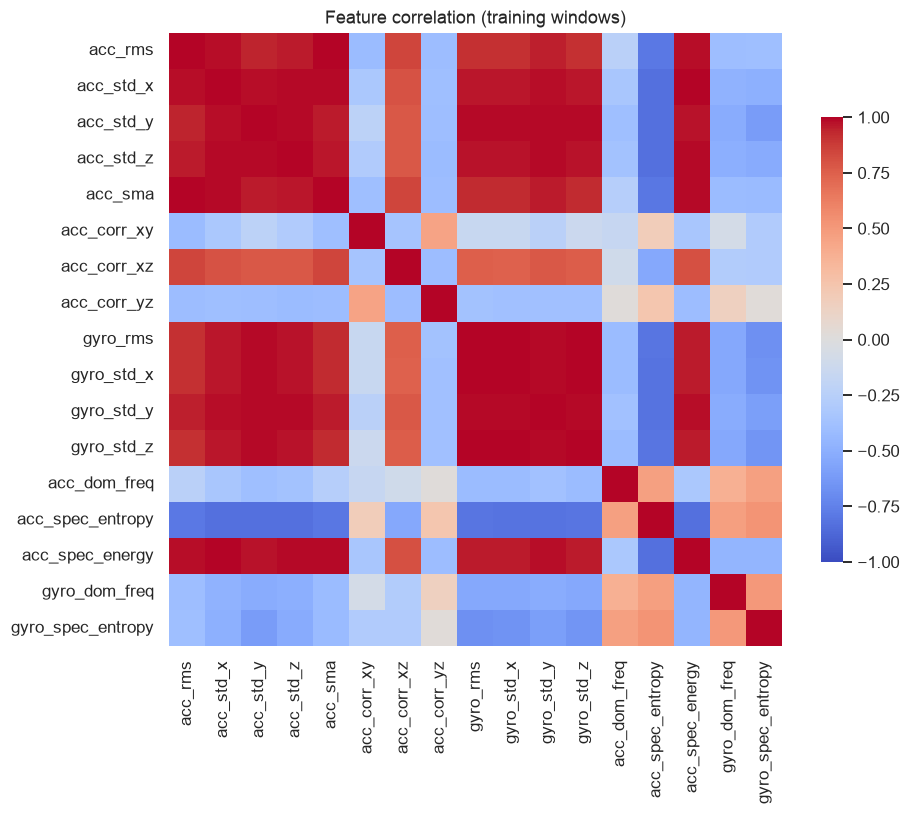

acc_sma              84.22
acc_rms              77.30
acc_std_x            53.15
acc_spec_energy      51.96
gyro_std_z           50.37
acc_std_y            46.28
gyro_std_x           43.68
gyro_rms             39.60
acc_std_z            38.12
gyro_std_y           25.44
gyro_spec_entropy     3.17
acc_corr_xz           2.80
acc_spec_entropy      1.86
acc_corr_xy           1.24
gyro_dom_freq         0.54
acc_dom_freq          0.44
acc_corr_yz           0.34


In [13]:
fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(train_feat[FEATURES].corr(), cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax,
            square=True, cbar_kws={"shrink": .7})
ax.set_title("Feature correlation (training windows)")
savefig(fig, "fig_feature_correlation"); plt.show()

# Fisher score (between-class / within-class variance) -> most discriminative features, training data only
def fisher_scores(Z: pd.DataFrame, y: pd.Series) -> pd.Series:
    mu = Z.mean()
    between = sum((y == c).sum() * (Z[y == c].mean() - mu) ** 2 for c in ACTIVITIES)
    within = sum(((Z[y == c] - Z[y == c].mean()) ** 2).sum() for c in ACTIVITIES)
    return (between / within).sort_values(ascending=False)

fisher = fisher_scores(Ztrain, train_feat.label)
print(fisher.round(2).to_string())
RESULTS["fisher_top"] = fisher.head(5).round(2).to_dict()

## 3. HMM Setup and Implementation

| Element | Our choice |
|---|---|
| Hidden states $Z$ | 4 activities: standing, walking, jumping, still |
| Observations $X$ | Z-scored 17-dim feature vector, one per 2 s window (1 s hop) |
| Transitions $A$ | $A_{ij}=P(z_t=j\mid z_{t-1}=i)$, 4×4 |
| Emissions $B$ | multivariate Gaussian per state with **diagonal covariance**: $b_j(x)=\prod_d \mathcal N(x_d;\mu_{jd},\sigma^2_{jd})$ |
| Initial $\pi$ | $\pi_i=P(z_1=i)$ |

**Why diagonal covariance:** a full 17×17 covariance per state needs 153 parameters per state, estimated from about 100 windows.
That would be badly conditioned and the matrices could become singular. A diagonal covariance needs only 17 variances per state.
A **variance floor** (1e-2 in standardised units) stops a state from collapsing onto a very tight cluster
(for example the near-constant *still* features), which would give infinite likelihoods and over-confident decoding.

**Algorithms and how they relate to the metrics**
* **Forward (and backward) algorithm**: computes $\log P(X\mid\lambda)$ in $O(TK^2)$. We use it as the **convergence criterion** for training, and backward gives the posteriors needed by EM.
* **Baum-Welch (EM)**: learns $\pi$, $A$ and the Gaussian parameters by maximising the likelihood over *multiple* sequences. Each iteration cannot decrease the likelihood. We stop when the gain is $<\varepsilon=10^{-4}$.
* **Viterbi**: returns the single most likely state *sequence* $\arg\max_Z P(Z\mid X)$. It gives one hard label per window, so it **directly produces the per-window predictions** behind accuracy, sensitivity, specificity and the confusion matrix. Through $A$, it can also smooth away isolated noisy windows that a per-window classifier would get wrong.

Everything runs in **log space** (`logsumexp`) to avoid numerical underflow on long sequences.

In [14]:
def logsumexp(a: np.ndarray, axis: int | None = None, keepdims: bool = False) -> np.ndarray:
    """Numerically stable log(sum(exp(a))) along `axis`."""
    m = np.max(a, axis=axis, keepdims=True)
    m = np.where(np.isfinite(m), m, 0.0)
    out = np.log(np.sum(np.exp(a - m), axis=axis, keepdims=True)) + m
    return out if keepdims else np.squeeze(out, axis=axis)


class GaussianHMM:
    """Hidden Markov Model with diagonal-covariance Gaussian emissions, implemented from scratch in numpy.

    Parameters
    ----------
    n_states : number of hidden states K.
    var_floor : lower bound on every emission variance (numerical stability).
    seed : random seed (only used for random initialisation).

    Attributes (after init/fit)
    ---------------------------
    pi : (K,) initial state probabilities.
    A : (K, K) transition matrix, rows sum to 1.
    means, vars : (K, D) Gaussian emission parameters.
    """

    def __init__(self, n_states: int, var_floor: float = 1e-2, seed: int = SEED) -> None:
        self.K = n_states
        self.var_floor = var_floor
        self.rng = np.random.default_rng(seed)
        self.pi: np.ndarray | None = None
        self.A: np.ndarray | None = None
        self.means: np.ndarray | None = None
        self.vars: np.ndarray | None = None
        self.history: list[float] = []

    # ------------------------------------------------------------------ initialisation
    def init_from_labels(self, X_seqs: list[np.ndarray], y_seqs: list[np.ndarray], smoothing: float = 1.0) -> "GaussianHMM":
        """Supervised (maximum-likelihood) initialisation from labelled sequences.

        Emissions: per-state mean/variance of the windows with that label.
        A, pi: transition / start counts plus `smoothing` pseudo-counts (Laplace), so no probability is exactly 0.
        """
        X, y = np.vstack(X_seqs), np.concatenate(y_seqs)
        self.means = np.array([X[y == k].mean(axis=0) for k in range(self.K)])
        self.vars = np.maximum(np.array([X[y == k].var(axis=0) for k in range(self.K)]), self.var_floor)
        trans = np.full((self.K, self.K), smoothing)
        start = np.full(self.K, smoothing)
        for ys in y_seqs:
            start[ys[0]] += 1
            np.add.at(trans, (ys[:-1], ys[1:]), 1)
        self.A = trans / trans.sum(axis=1, keepdims=True)
        self.pi = start / start.sum()
        return self

    # ------------------------------------------------------------------ core recursions
    def log_emission(self, X: np.ndarray) -> np.ndarray:
        """log b_j(x_t) for every t, j -> (T, K)."""
        diff = X[:, None, :] - self.means[None, :, :]                       # (T, K, D)
        return -0.5 * (np.sum(np.log(2 * np.pi * self.vars), axis=1)[None, :]
                       + np.sum(diff ** 2 / self.vars[None, :, :], axis=2))

    def forward(self, logB: np.ndarray) -> tuple[np.ndarray, float]:
        """Log-space forward pass. Returns log_alpha (T, K) and log P(X | model)."""
        T = logB.shape[0]
        logA = np.log(self.A)
        la = np.empty((T, self.K))
        la[0] = np.log(self.pi) + logB[0]
        for t in range(1, T):
            la[t] = logsumexp(la[t - 1][:, None] + logA, axis=0) + logB[t]
        return la, float(logsumexp(la[-1]))

    def backward(self, logB: np.ndarray) -> np.ndarray:
        """Log-space backward pass. Returns log_beta (T, K)."""
        T = logB.shape[0]
        logA = np.log(self.A)
        lb = np.zeros((T, self.K))
        for t in range(T - 2, -1, -1):
            lb[t] = logsumexp(logA + (logB[t + 1] + lb[t + 1])[None, :], axis=1)
        return lb

    def score(self, X: np.ndarray) -> float:
        """log P(X | model) via the forward algorithm."""
        return self.forward(self.log_emission(X))[1]

    def posteriors(self, X: np.ndarray) -> tuple[np.ndarray, np.ndarray, float]:
        """E-step for one sequence: gamma (T,K), summed xi (K,K), and the log-likelihood."""
        logB = self.log_emission(X)
        la, ll = self.forward(logB)
        lb = self.backward(logB)
        gamma = np.exp(la + lb - ll)
        logA = np.log(self.A)
        # xi_t(i,j) ∝ alpha_t(i) A_ij b_j(x_{t+1}) beta_{t+1}(j); summed over t
        lxi = la[:-1, :, None] + logA[None] + (logB[1:] + lb[1:])[:, None, :] - ll
        xi_sum = np.exp(logsumexp(lxi, axis=0)) if len(X) > 1 else np.zeros((self.K, self.K))
        return gamma, xi_sum, ll

    # ------------------------------------------------------------------ learning
    def fit(self, X_seqs: list[np.ndarray], max_iter: int = 200, tol: float = 1e-4, verbose: bool = True) -> "GaussianHMM":
        """Baum-Welch (EM) over multiple independent sequences.

        Stops when the improvement in total log-likelihood is < `tol` or after `max_iter` iterations.
        The total log-likelihood of every iteration is stored in `self.history`.
        """
        if self.means is None:  # random init fallback: K random windows as means, global variance
            X = np.vstack(X_seqs)
            self.means = X[self.rng.choice(len(X), self.K, replace=False)]
            self.vars = np.tile(np.maximum(X.var(axis=0), self.var_floor), (self.K, 1))
            self.A = np.full((self.K, self.K), 1 / self.K); self.pi = np.full(self.K, 1 / self.K)
        self.history, self.converged_ = [], False
        prev = -np.inf
        for it in range(max_iter):
            start = np.zeros(self.K); trans = np.zeros((self.K, self.K))
            g_sum = np.zeros(self.K); gx = np.zeros_like(self.means); gx2 = np.zeros_like(self.means)
            total_ll = 0.0
            for X in X_seqs:                                    # E-step
                gamma, xi_sum, ll = self.posteriors(X)
                total_ll += ll
                start += gamma[0]; trans += xi_sum
                g_sum += gamma.sum(axis=0); gx += gamma.T @ X; gx2 += gamma.T @ (X ** 2)
            self.history.append(total_ll)
            if verbose and (it < 3 or it % 5 == 0):
                print(f"iter {it:3d}  total log-likelihood = {total_ll:12.4f}")
            if total_ll - prev < tol:                           # convergence check (likelihood of current params)
                self.converged_ = True
                if verbose: print(f"converged at iter {it} (Δ = {total_ll - prev:.2e} < {tol})")
                break
            prev = total_ll
            # M-step (keep tiny floors so no probability is exactly 0)
            self.pi = np.maximum(start / start.sum(), 1e-10); self.pi /= self.pi.sum()
            self.A = np.maximum(trans / trans.sum(axis=1, keepdims=True), 1e-10)
            self.A /= self.A.sum(axis=1, keepdims=True)
            self.means = gx / g_sum[:, None]
            self.vars = np.maximum(gx2 / g_sum[:, None] - self.means ** 2, self.var_floor)
        self.n_iter_ = len(self.history)
        return self

    # ------------------------------------------------------------------ decoding
    def viterbi(self, X: np.ndarray) -> tuple[np.ndarray, float]:
        """Most likely state path (log-space Viterbi with back-pointers). Returns (path, log P(path, X))."""
        logB = self.log_emission(X)
        logA = np.log(self.A)
        T = len(X)
        delta = np.empty((T, self.K)); psi = np.zeros((T, self.K), dtype=int)
        delta[0] = np.log(self.pi) + logB[0]
        for t in range(1, T):
            scores = delta[t - 1][:, None] + logA          # (from i, to j)
            psi[t] = np.argmax(scores, axis=0)
            delta[t] = scores[psi[t], np.arange(self.K)] + logB[t]
        path = np.empty(T, dtype=int); path[-1] = np.argmax(delta[-1])
        for t in range(T - 2, -1, -1):
            path[t] = psi[t + 1, path[t + 1]]
        return path, float(delta[-1, path[-1]])

### 3.1 Sanity checks (unit tests)

Before training we check the implementation on a tiny random HMM (K = 3 states, T = 6, 2-D observations):
1. **Viterbi = brute force.** Enumerate all $3^6 = 729$ paths and compare the best path and its score.
2. **Forward = brute force.** $\log\sum_{Z}P(X,Z)$ over all paths must equal the forward log-likelihood.
3. **Posteriors are valid.** Each row of γ sums to 1.

In [15]:
def _brute_force(h: GaussianHMM, X: np.ndarray) -> tuple[np.ndarray, float, float]:
    """Enumerate all K^T paths: best path, its log-prob, and log-sum over paths."""
    logB, logA = h.log_emission(X), np.log(h.A)
    best, best_lp, all_lp = None, -np.inf, []
    for path in itertools.product(range(h.K), repeat=len(X)):
        lp = np.log(h.pi[path[0]]) + logB[0, path[0]]
        lp += sum(logA[path[t - 1], path[t]] + logB[t, path[t]] for t in range(1, len(X)))
        all_lp.append(lp)
        if lp > best_lp: best, best_lp = np.array(path), lp
    return best, best_lp, float(logsumexp(np.array(all_lp)))

def run_sanity_checks(n_trials: int = 5) -> None:
    trng = np.random.default_rng(0)
    for trial in range(n_trials):
        h = GaussianHMM(3, var_floor=1e-3)
        h.pi = trng.dirichlet(np.ones(3)); h.A = trng.dirichlet(np.ones(3), size=3)
        h.means = trng.normal(size=(3, 2)); h.vars = trng.uniform(0.3, 2, size=(3, 2))
        X = trng.normal(size=(6, 2))
        path, lp = h.viterbi(X)
        bf_path, bf_lp, bf_ll = _brute_force(h, X)
        assert np.array_equal(path, bf_path) and np.isclose(lp, bf_lp), "Viterbi != brute force"
        assert np.isclose(h.score(X), bf_ll), "Forward != brute force"
        gamma, _, _ = h.posteriors(X)
        assert np.allclose(gamma.sum(axis=1), 1.0), "gamma rows do not sum to 1"
    print(f"PASS: Viterbi and forward match brute force on {n_trials} random HMMs; posteriors normalised.")

run_sanity_checks()

PASS: Viterbi and forward match brute force on 5 random HMMs; posteriors normalised.


### 3.2 Building training sequences

Each training recording contains **one** activity, so it has no real transitions. If we estimated $A$ from isolated recordings,
we would get a purely diagonal matrix (no transitions at all). To give the HMM a temporal context that includes transitions,
we **concatenate whole recordings into longer sequences**. Each of the 12 training sequences holds the *n*-th recording of every
activity, in a random order (seed 42). The windows of each recording stay contiguous and in time order.

What this means (and the report says so): the self-transition probabilities reflect how long *our recordings* last
(≈ 8 windows ≈ 8–9 s per activity bout). The off-diagonal probabilities reflect a **random, roughly uniform activity order**,
not a behaviour pattern observed in real life. We add **Laplace smoothing (+1 pseudo-count)** so no transition is impossible.

In [16]:
def build_sequences(feat: pd.DataFrame, Z: pd.DataFrame, rng: np.random.Generator) -> tuple[list, list, list]:
    """Group recordings by index (01..12); each group = one sequence of 4 recordings (one per activity) in random order."""
    feat = feat.assign(idx=feat.recording.str.split("_").str[1])
    X_seqs, y_seqs, orders = [], [], []
    for idx in sorted(feat.idx.unique()):
        order = list(rng.permutation(ACTIVITIES))
        rows = pd.concat([feat[(feat.idx == idx) & (feat.label == lab)].sort_values("win_idx") for lab in order])
        X_seqs.append(Z.loc[rows.index].to_numpy())
        y_seqs.append(rows.label.map(ACTIVITIES.index).to_numpy())
        orders.append(f"seq {idx}: " + " → ".join(order))
    return X_seqs, y_seqs, orders

X_train_seqs, y_train_seqs, seq_orders = build_sequences(train_feat, Ztrain, rng)
print("\n".join(seq_orders[:4]), "\n...")
print(f"{len(X_train_seqs)} sequences, lengths {[len(s) for s in X_train_seqs]}")

seq 01: still → jumping → walking → standing
seq 02: still → jumping → standing → walking
seq 03: standing → still → jumping → walking
seq 04: jumping → still → standing → walking 
...
12 sequences, lengths [32, 35, 33, 31, 32, 32, 34, 32, 32, 33, 32, 34]


### 3.3 Training: supervised initialisation, then Baum-Welch refinement

1. **Initialise** $\mu,\sigma^2$ from the labelled windows, and $A,\pi$ from the label sequences (with smoothing).
2. **Refine** all parameters with Baum-Welch over the 12 sequences. Baum-Welch is unsupervised and never sees the labels.
3. Because EM may permute or re-purpose states, we **map hidden states to activities** afterwards with the
   Hungarian algorithm on the training confusion matrix (training data only).

In [17]:
hmm_init = GaussianHMM(len(ACTIVITIES), var_floor=1e-2).init_from_labels(X_train_seqs, y_train_seqs, smoothing=1.0)
A_init = hmm_init.A.copy()

hmm = GaussianHMM(len(ACTIVITIES), var_floor=1e-2).init_from_labels(X_train_seqs, y_train_seqs, smoothing=1.0)
hmm.fit(X_train_seqs, max_iter=200, tol=1e-4)

hist = np.array(hmm.history)
diffs = np.diff(hist)
assert np.all(diffs > -1e-6), "log-likelihood decreased!"
assert np.allclose(hmm.A.sum(axis=1), 1) and np.isclose(hmm.pi.sum(), 1), "A / pi not normalised"
print(f"PASS: log-likelihood non-decreasing over {len(hist)} iterations (min Δ = {diffs.min():.2e}); rows of A and pi sum to 1.")
print(f"log-likelihood: init {hist[0]:.2f} -> final {hist[-1]:.2f}; converged = {hmm.converged_}")
RESULTS["bw"] = {"iterations": int(hmm.n_iter_), "converged": bool(hmm.converged_), "ll_init": round(float(hist[0]), 2),
                 "ll_final": round(float(hist[-1]), 2), "tol": 1e-4, "max_iter": 200, "var_floor": 1e-2}

iter   0  total log-likelihood =     639.7130
iter   1  total log-likelihood =     717.9170
iter   2  total log-likelihood =     748.9634
iter   5  total log-likelihood =     786.8989
converged at iter 5 (Δ = 5.53e-11 < 0.0001)
PASS: log-likelihood non-decreasing over 6 iterations (min Δ = 5.53e-11); rows of A and pi sum to 1.
log-likelihood: init 639.71 -> final 786.90; converged = True


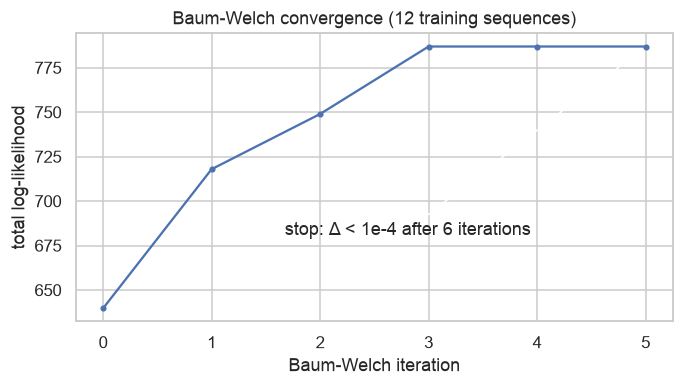

In [18]:
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(np.arange(len(hist)), hist, "o-", ms=3)
ax.set(xlabel="Baum-Welch iteration", ylabel="total log-likelihood", title="Baum-Welch convergence (12 training sequences)")
ax.annotate(f"stop: Δ < 1e-4 after {len(hist)} iterations", xy=(len(hist) - 1, hist[-1]), xytext=(0.35, 0.3),
            textcoords="axes fraction", arrowprops=dict(arrowstyle="->"))
savefig(fig, "fig_bw_convergence"); plt.show()

In [19]:
def map_states(model: GaussianHMM, X_seqs: list, y_seqs: list) -> dict[int, int]:
    """Map hidden state -> activity index with the Hungarian algorithm on the training confusion matrix."""
    C = np.zeros((model.K, len(ACTIVITIES)), dtype=int)
    for X, y in zip(X_seqs, y_seqs):
        path, _ = model.viterbi(X)
        np.add.at(C, (path, y), 1)
    rows, cols = linear_sum_assignment(-C)
    return dict(zip(rows.tolist(), cols.tolist()))

state_map = map_states(hmm, X_train_seqs, y_train_seqs)
print("hidden state -> activity:", {s: ACTIVITIES[a] for s, a in state_map.items()})
RESULTS["state_map"] = {int(s): ACTIVITIES[a] for s, a in state_map.items()}

# re-order the parameters so that state index k == ACTIVITIES[k] (only for readable plots)
perm = [s for s, _ in sorted(state_map.items(), key=lambda kv: kv[1])]
hmm.pi, hmm.A = hmm.pi[perm], hmm.A[np.ix_(perm, perm)]
hmm.means, hmm.vars = hmm.means[perm], hmm.vars[perm]

np.savez(PROC / "hmm_params.npz", pi=hmm.pi, A=hmm.A, means=hmm.means, vars=hmm.vars,
         states=np.array(ACTIVITIES), features=np.array(FEATURES))
pd.DataFrame(hmm.A, index=ACTIVITIES, columns=ACTIVITIES).round(3)

hidden state -> activity: {0: 'standing', 1: 'walking', 2: 'jumping', 3: 'still'}


,standing,walking,jumping,still
standing,0.874,0.049,0.039,0.039
walking,0.054,0.925,0.011,0.011
jumping,0.010,0.031,0.887,0.072
still,0.046,0.011,0.057,0.885


## 4. Model components: transition and emission probabilities

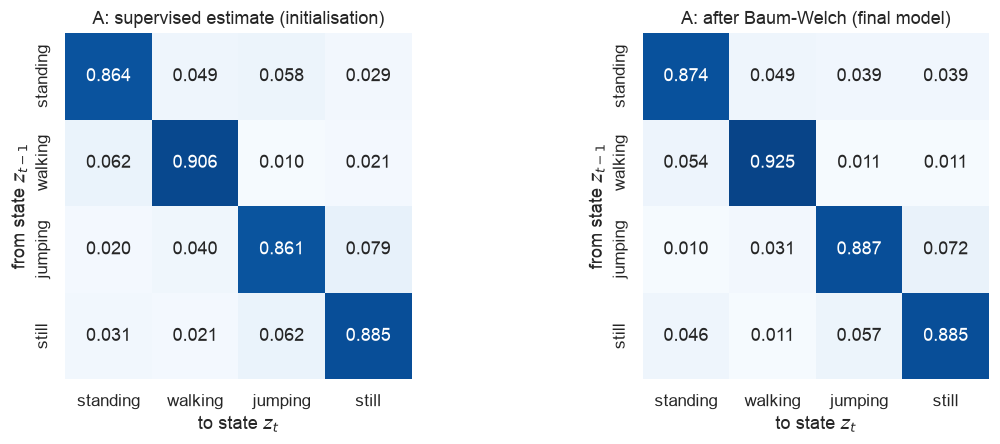

pi = {'standing': np.float64(0.333), 'walking': np.float64(0.333), 'jumping': np.float64(0.167), 'still': np.float64(0.167)}


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, M, title in ((axes[0], A_init, "A: supervised estimate (initialisation)"),
                     (axes[1], hmm.A, "A: after Baum-Welch (final model)")):
    sns.heatmap(M, annot=True, fmt=".3f", cmap="Blues", vmin=0, vmax=1, ax=ax, cbar=False,
                xticklabels=ACTIVITIES, yticklabels=ACTIVITIES, square=True)
    ax.set(xlabel="to state $z_t$", ylabel="from state $z_{t-1}$", title=title)
fig.tight_layout(); savefig(fig, "fig_transition_matrix"); plt.show()
print("pi =", dict(zip(ACTIVITIES, hmm.pi.round(3))))
RESULTS["A"] = pd.DataFrame(hmm.A, index=ACTIVITIES, columns=ACTIVITIES).round(3).to_dict()
RESULTS["A_init"] = pd.DataFrame(A_init, index=ACTIVITIES, columns=ACTIVITIES).round(3).to_dict()
RESULTS["pi"] = dict(zip(ACTIVITIES, hmm.pi.round(3).tolist()))

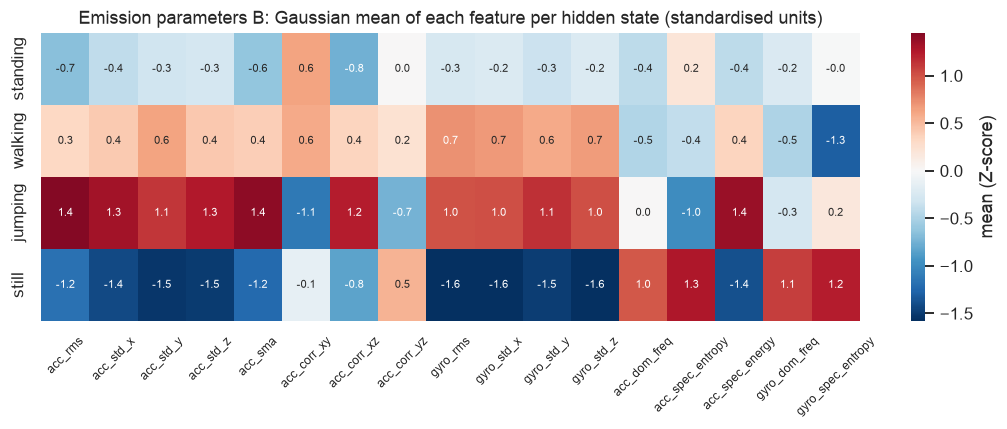

In [21]:
fig, ax = plt.subplots(figsize=(12, 3.4))
sns.heatmap(pd.DataFrame(hmm.means, index=ACTIVITIES, columns=FEATURES), cmap="RdBu_r", center=0, annot=True,
            fmt=".1f", annot_kws={"size": 7}, ax=ax, cbar_kws={"label": "mean (Z-score)"})
ax.set_title("Emission parameters B: Gaussian mean of each feature per hidden state (standardised units)")
ax.tick_params(axis="x", labelrotation=45, labelsize=8)
savefig(fig, "fig_emission_means"); plt.show()

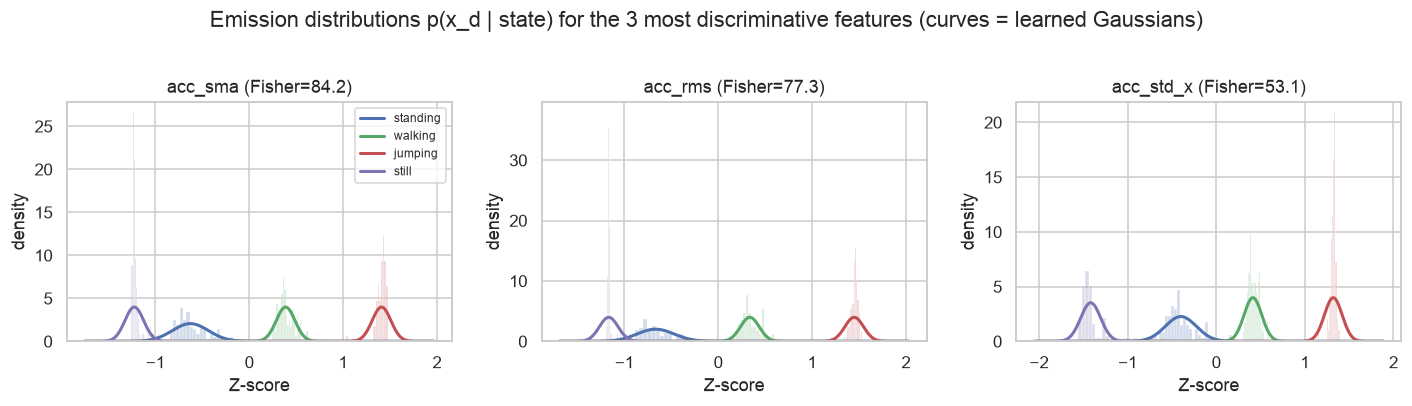

In [22]:
TOP3 = fisher.index[:3].tolist()
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, feat in zip(axes, TOP3):
    d = FEATURES.index(feat)
    xs = np.linspace(Ztrain[feat].min() - 0.5, Ztrain[feat].max() + 0.5, 600)
    for k, lab in enumerate(ACTIVITIES):
        ax.hist(Ztrain.loc[train_feat.label == lab, feat], bins=25, density=True, alpha=0.25, color=PALETTE[lab])
        mu, sd = hmm.means[k, d], np.sqrt(hmm.vars[k, d])
        ax.plot(xs, np.exp(-0.5 * ((xs - mu) / sd) ** 2) / (sd * np.sqrt(2 * np.pi)), color=PALETTE[lab], lw=2, label=lab)
    ax.set(title=f"{feat} (Fisher={fisher[feat]:.1f})", xlabel="Z-score", ylabel="density")
axes[0].legend(fontsize=8)
fig.suptitle("Emission distributions p(x_d | state) for the 3 most discriminative features (curves = learned Gaussians)", y=1.02)
fig.tight_layout(); savefig(fig, "fig_emission_distributions"); plt.show()

## 5. Evaluation on unseen data

**How the unseen data was obtained.** In a **separate session** (10:59–11:06, about 20 minutes after the last training
recording at 10:40, per `Metadata.csv`) the same participant recorded three *new* continuous recordings (about 31–45 s each) on the same phone,
in which the activities follow each other without stopping: `standing → walking → jumping → still` (×2) and `still → jumping → walking → standing` (×1).
None of these recordings is used for training, normalisation or any design decision.

Unlike the training files, these sessions contain **real activity transitions**, plus the gesture of putting the phone on (or picking it up from)
the table, which we label `transition`. Sensor Logger's `Annotation.csv` was empty, so the segment boundaries in
`data/labels/test_segments.csv` were marked by hand on the motion-energy plot, at times relative to the start of each recording.
Windows whose majority label is `transition` are decoded but **excluded from the metrics**, because none of the 4 states describes them.

In [23]:
segments = pd.read_csv(LABELS_DIR / "test_segments.csv")

def label_samples(df: pd.DataFrame, rec_id: str, trim_s: float = TRIM_S) -> pd.Series:
    """Per-sample ground truth from the segment table (segment times are relative to the untrimmed recording)."""
    t_orig = df["t"] + trim_s
    lab = pd.Series("unlabelled", index=df.index)
    for _, s in segments[segments.recording == rec_id].iterrows():
        lab[(t_orig >= s.start_s) & (t_orig < s.end_s)] = s.label
    return lab

test_inv = inventory(RAW_TEST)
test_recs, test_feats = {}, []
for _, row in test_inv.iterrows():
    df = clean_recording(RAW_TEST / row.folder)
    df.insert(1, "label", label_samples(df, row.recording))
    assert (df.label != "unlabelled").all(), f"unlabelled samples in {row.recording}"
    test_recs[row.recording] = df
    df.to_csv(PROC / "test" / f"{row.recording}.csv", index=False)
    test_feats.append(features_for_recording(df, row.recording))
test_feat = pd.concat(test_feats, ignore_index=True)
test_feat.to_csv(PROC / "features_test.csv", index=False)

Ztest = scaler.transform(test_feat[FEATURES])           # TRAINING mean/std, no refit
display(test_inv[["recording", "device", "detected_hz", "raw_duration_s"]].round(2))
print("test windows per label:"); print(test_feat.label.value_counts().to_string())
RESULTS["test_files"] = test_inv[["recording", "detected_hz", "raw_duration_s"]].round(2).to_dict(orient="records")

,recording,device,detected_hz,raw_duration_s
0,standing_walking_jumping_still_01,iPhone XS,49.77,45.33
1,standing_walking_jumping_still_02,iPhone XS,49.77,31.58
2,still_jumping_walking_standing_01,iPhone XS,49.77,35.36


test windows per label:
label
walking       29
jumping       27
standing      18
still         14
transition     8


In [24]:
def decode(model: GaussianHMM, Z: pd.DataFrame, feat: pd.DataFrame) -> np.ndarray:
    """Viterbi-decode each recording separately (one sequence per recording), return activity names per window."""
    pred = pd.Series(index=feat.index, dtype=object)
    for rec, idx in feat.groupby("recording", sort=False).groups.items():
        order = feat.loc[idx].sort_values("win_idx").index
        path, _ = model.viterbi(Z.loc[order].to_numpy())
        pred[order] = [ACTIVITIES[s] for s in path]
    return pred.to_numpy()


def evaluate(y_true: np.ndarray, y_pred: np.ndarray) -> tuple[pd.DataFrame, np.ndarray]:
    """Per-class one-vs-rest sensitivity/specificity/accuracy + overall accuracy, and the confusion matrix."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    cm = np.array([[np.sum((y_true == a) & (y_pred == b)) for b in ACTIVITIES] for a in ACTIVITIES])
    N, rows = cm.sum(), []
    for k, lab in enumerate(ACTIVITIES):
        TP = cm[k, k]; FN = cm[k].sum() - TP; FP = cm[:, k].sum() - TP; TN = N - TP - FN - FP
        rows.append({"State (Activity)": lab, "Number of Samples": int(cm[k].sum()),
                     "Sensitivity": TP / (TP + FN) if TP + FN else np.nan,
                     "Specificity": TN / (TN + FP) if TN + FP else np.nan,
                     "Overall Accuracy": (TP + TN) / N})
    table = pd.DataFrame(rows)
    table.loc[len(table)] = {"State (Activity)": "All (multi-class)", "Number of Samples": int(N),
                             "Sensitivity": table.Sensitivity.mean(), "Specificity": table.Specificity.mean(),
                             "Overall Accuracy": np.trace(cm) / N}
    return table, cm

In [25]:
# ---- test set (unseen) ----
test_feat["pred"] = decode(hmm, Ztest, test_feat)
mask = test_feat.label.isin(ACTIVITIES)
test_table, cm_test = evaluate(test_feat.label[mask], test_feat.pred[mask])
print(f"TEST: {mask.sum()} labelled windows ({(~mask).sum()} 'transition' windows excluded)")
display(test_table.round(3))

# ---- training set (same decoding, training sequences) ----
y_tr_true = np.concatenate([[ACTIVITIES[i] for i in y] for y in y_train_seqs])
y_tr_pred = np.concatenate([[ACTIVITIES[i] for i in hmm.viterbi(X)[0]] for X in X_train_seqs])
train_table, cm_train = evaluate(y_tr_true, y_tr_pred)
print("TRAIN:"); display(train_table.round(3))

RESULTS["test_table"] = test_table.round(4).to_dict(orient="records")
RESULTS["train_table"] = train_table.round(4).to_dict(orient="records")
RESULTS["cm_test"] = cm_test.tolist(); RESULTS["cm_train"] = cm_train.tolist()
RESULTS["test_excluded_transition_windows"] = int((~mask).sum())
RESULTS["per_file_acc"] = {r: round(float((g.label == g.pred)[g.label.isin(ACTIVITIES)].mean()), 4)
                           for r, g in test_feat.groupby("recording")}
print("per-file test accuracy:", RESULTS["per_file_acc"])

TEST: 88 labelled windows (8 'transition' windows excluded)


,State (Activity),Number of Samples,Sensitivity,Specificity,Overall Accuracy
0,standing,18,0.889,0.914,0.909
1,walking,29,1.000,0.932,0.955
2,jumping,27,0.926,1.000,0.977
3,still,14,0.571,1.000,0.932
4,All (multi-class),88,0.847,0.962,0.886


TRAIN:


,State (Activity),Number of Samples,Sensitivity,Specificity,Overall Accuracy
0,standing,100,0.990,0.983,0.985
1,walking,98,1.000,0.997,0.997
2,jumping,98,1.000,1.000,1.000
3,still,96,0.948,1.000,0.987
4,All (multi-class),392,0.984,0.995,0.985


per-file test accuracy: {'standing_walking_jumping_still_01': 0.9189, 'standing_walking_jumping_still_02': 0.8261, 'still_jumping_walking_standing_01': 0.8929}


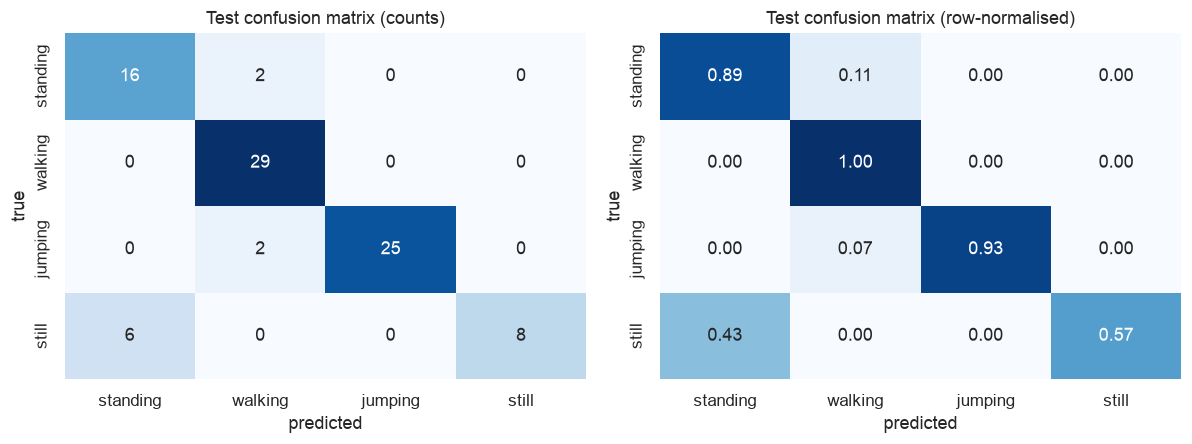

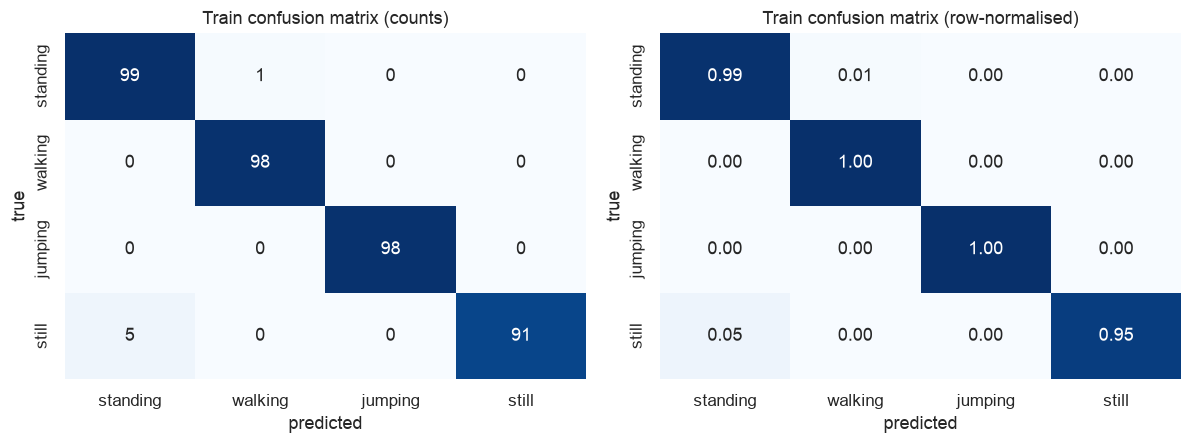

In [26]:
def plot_confusion(cm: np.ndarray, title: str, name: str) -> None:
    """Side-by-side confusion matrix: counts and row-normalised (recall) values."""
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
    norm = cm / cm.sum(axis=1, keepdims=True)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0], cbar=False, xticklabels=ACTIVITIES, yticklabels=ACTIVITIES)
    sns.heatmap(norm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=axes[1], cbar=False,
                xticklabels=ACTIVITIES, yticklabels=ACTIVITIES)
    for ax, sub in zip(axes, ["counts", "row-normalised"]):
        ax.set(xlabel="predicted", ylabel="true", title=f"{title} ({sub})")
    fig.tight_layout(); savefig(fig, name); plt.show()

plot_confusion(cm_test, "Test confusion matrix", "fig_confusion_test")
plot_confusion(cm_train, "Train confusion matrix", "fig_confusion_train")

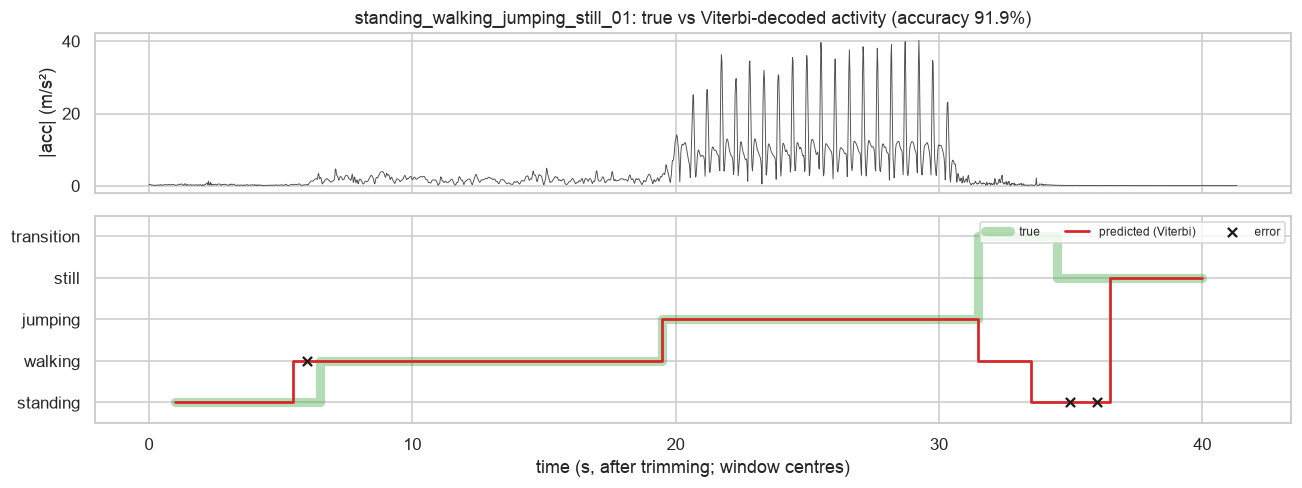

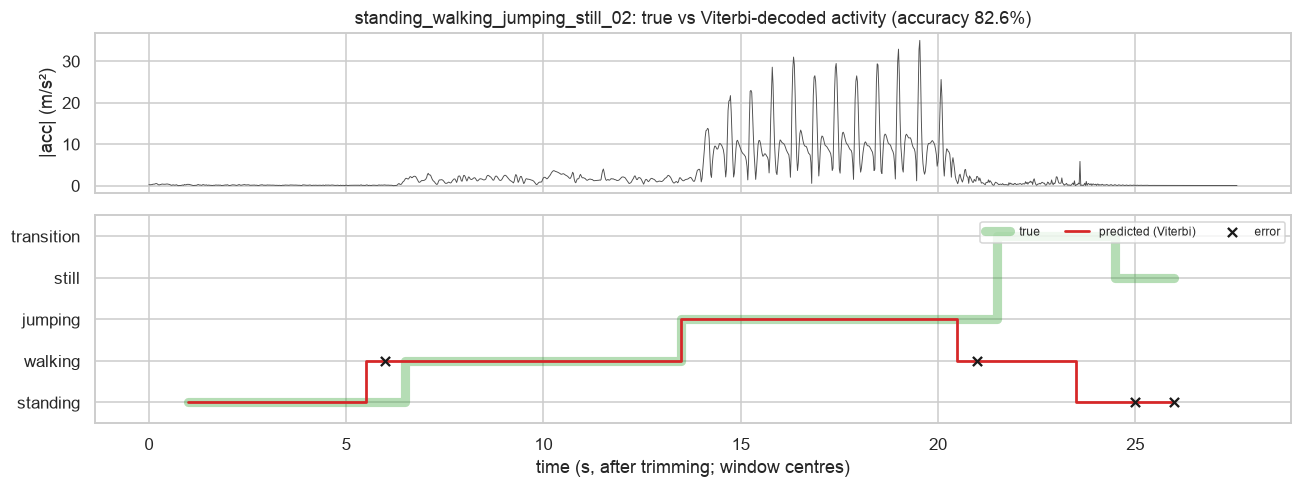

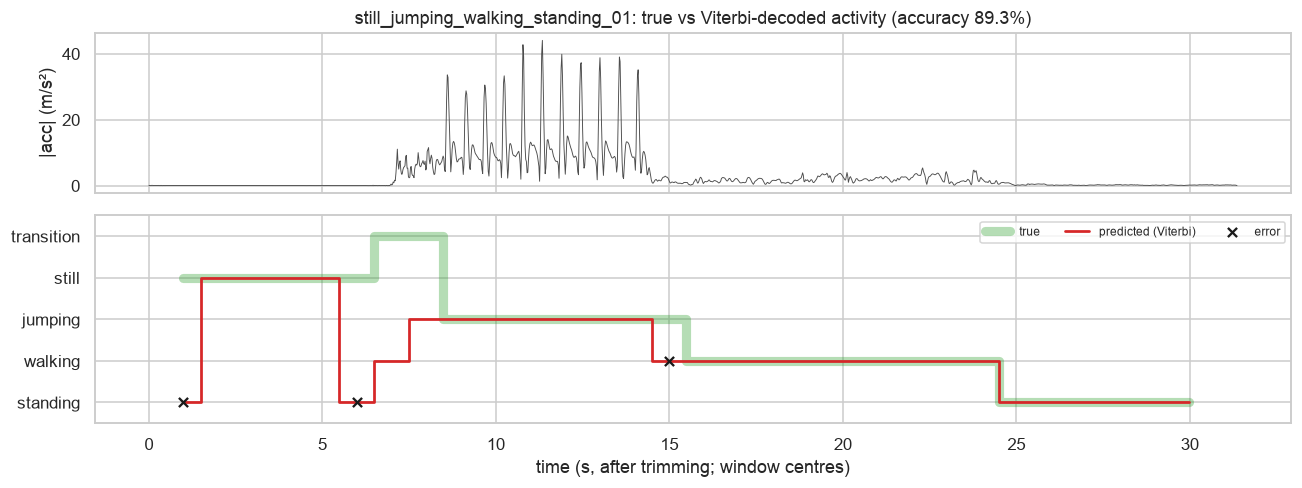

In [27]:
def plot_decoded(rec: str) -> plt.Figure:
    """Acc-magnitude trace + true vs Viterbi-decoded activity per window for one test recording."""
    g = test_feat[test_feat.recording == rec].sort_values("win_idx")
    df = test_recs[rec]
    levels = ACTIVITIES + ["transition"]
    fig, (ax0, ax1) = plt.subplots(2, 1, figsize=(12, 4.6), sharex=True, gridspec_kw={"height_ratios": [1, 1.3]})
    ax0.plot(df.t, np.linalg.norm(df[["acc_x", "acc_y", "acc_z"]], axis=1), lw=0.6, c="0.3")
    ax0.set(ylabel="|acc| (m/s²)", title=f"{rec}: true vs Viterbi-decoded activity "
            f"(accuracy {RESULTS['per_file_acc'][rec]:.1%})")
    y_true = g.label.map(levels.index); y_pred = g.pred.map(levels.index)
    ax1.step(g.t_center, y_true, where="mid", lw=6, alpha=0.35, c="tab:green", label="true")
    ax1.step(g.t_center, y_pred, where="mid", lw=1.8, c="tab:red", label="predicted (Viterbi)")
    wrong = g[(g.label != g.pred) & g.label.isin(ACTIVITIES)]
    ax1.scatter(wrong.t_center, wrong.pred.map(levels.index), marker="x", c="k", zorder=5, label="error")
    ax1.set_yticks(range(len(levels)), levels); ax1.set_xlabel("time (s, after trimming; window centres)")
    ax1.legend(loc="upper right", fontsize=8, ncol=3); ax1.set_ylim(-0.5, len(levels) - 0.5)
    fig.tight_layout()
    return fig

for i, rec in enumerate(test_inv.recording):
    fig = plot_decoded(rec); savefig(fig, f"fig_decoded_{rec}"); plt.show()

### 5.1 Error diagnosis: where do the mistakes happen?

For each misclassified window we measure the distance from its centre to the nearest labelled segment boundary
(boundaries include the edges of the excluded `transition` gaps).

In [28]:
def boundary_distance(row: pd.Series) -> float:
    """Distance (s) from a window centre (in untrimmed time) to the nearest hand-labelled boundary of its recording."""
    seg = segments[segments.recording == row.recording]
    edges = np.unique(np.r_[seg.start_s, seg.end_s])
    return float(np.min(np.abs(edges - (row.t_center + TRIM_S))))

errs = test_feat[mask & (test_feat.label != test_feat.pred)].copy()
errs["dist_to_boundary_s"] = errs.apply(boundary_distance, axis=1)
display(errs[["recording", "t_center", "label", "pred", "dist_to_boundary_s"]].round(2))
near = int((errs.dist_to_boundary_s <= WIN_S).sum())
print(f"{near}/{len(errs)} errors lie within {WIN_S:.0f} s (one window length) of a segment boundary")
RESULTS["errors"] = {"n": int(len(errs)), "near_boundary": near,
                     "pairs": errs.groupby(["label", "pred"]).size().rename("n").reset_index().to_dict(orient="records")}

,recording,t_center,label,pred,dist_to_boundary_s
5,standing_walking_jumping_still_01,5.99,standing,walking,0.01
34,standing_walking_jumping_still_01,34.99,still,standing,0.01
35,standing_walking_jumping_still_01,35.99,still,standing,0.99
45,standing_walking_jumping_still_02,5.99,standing,walking,0.01
60,standing_walking_jumping_still_02,20.99,jumping,walking,0.01
64,standing_walking_jumping_still_02,24.99,still,standing,0.49
65,standing_walking_jumping_still_02,25.99,still,standing,1.49
66,still_jumping_walking_standing_01,0.99,still,standing,2.99
71,still_jumping_walking_standing_01,5.99,still,standing,0.51
80,still_jumping_walking_standing_01,14.99,jumping,walking,0.01


9/10 errors lie within 2 s (one window length) of a segment boundary


### 5.2 Ablation: is the temporal model useful?

For the discussion only (the final model was fixed *before* looking at test results, so nothing is tuned on test data), we compare against:
* the **supervised-only** HMM (the labelled initialisation, without Baum-Welch);
* a **frame-wise Gaussian classifier**: the same emissions, but each window classified on its own (no transition matrix).

In [29]:
def framewise(model: GaussianHMM, Z: pd.DataFrame) -> np.ndarray:
    """Per-window argmax of the emission likelihood (ignores A and pi)."""
    return np.array(ACTIVITIES)[np.argmax(model.log_emission(Z.to_numpy()), axis=1)]

ablation = {
    "HMM, supervised init + Baum-Welch (final)": test_table.iloc[-1]["Overall Accuracy"],
    "HMM, supervised init only": evaluate(test_feat.label[mask], decode(hmm_init, Ztest, test_feat)[mask])[0].iloc[-1]["Overall Accuracy"],
    "Frame-wise Gaussian (no transitions)": evaluate(test_feat.label[mask], framewise(hmm, Ztest)[mask])[0].iloc[-1]["Overall Accuracy"],
}
ablation = pd.Series(ablation, name="test accuracy").round(4)
display(ablation.to_frame())
RESULTS["ablation"] = ablation.to_dict()

,test accuracy
"HMM, supervised init + Baum-Welch (final)",0.8864
"HMM, supervised init only",0.9205
Frame-wise Gaussian (no transitions),0.8864


In [30]:
(PROC / "results.json").write_text(json.dumps(RESULTS, indent=2, default=float))
print("Saved results to data/processed/results.json and figures to figures/:")
print(sorted(p.name for p in FIG.glob("*.png")))

Saved results to data/processed/results.json and figures to figures/:
['fig_bw_convergence.png', 'fig_confusion_test.png', 'fig_confusion_train.png', 'fig_decoded_standing_walking_jumping_still_01.png', 'fig_decoded_standing_walking_jumping_still_02.png', 'fig_decoded_still_jumping_walking_standing_01.png', 'fig_emission_distributions.png', 'fig_emission_means.png', 'fig_feature_boxplots.png', 'fig_feature_correlation.png', 'fig_raw_samples.png', 'fig_sampling_rates.png', 'fig_transition_matrix.png']


## 6. Summary

The interpretation and discussion of these results (easiest and hardest activities, realism of the transitions, effect of noise
and sampling rate, improvements) are in `report/report.docx`. Every number there comes from `data/processed/results.json`,
which this notebook writes.